In [13]:
# Model Training and Comparison
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib
import os
print("Libraries successfully imported!")

Libraries successfully imported!


In [20]:
X_train=pd.read_csv("../data/processed/X_train.csv")
X_test=pd.read_csv("../data/processed/X_test.csv")
y_train=pd.read_csv("../data/processed/y_train.csv")["MatchResult"]
y_test=pd.read_csv("../data/processed/y_test.csv")["MatchResult"]
print("X_Train: ", X_train.shape)
print("X_Test: ", X_test.shape)
print("Training target distribution: ", y_train.value_counts())
print("Testing target distribution: ", y_test.value_counts())

X_Train:  (13337, 15)
X_Test:  (3335, 15)
Training target distribution:  MatchResult
HW    6097
AW    3924
D     3316
Name: count, dtype: int64
Testing target distribution:  MatchResult
HW    1407
AW    1180
D      748
Name: count, dtype: int64


In [21]:
split=int(len(X_train)*0.8)
X_fit=X_train.iloc[:split].copy()
X_val=X_train.iloc[split:].copy()
y_fit=y_train.iloc[:split].copy()
y_val=y_train.iloc[split:].copy()
print("Model Training Data: ", X_fit.shape)
print("Validation Data: ", X_val.shape)
print("Training period target Distribution: ", y_fit.value_counts())
print("Validation period target distribution: ", y_val.value_counts())

Model Training Data:  (10669, 15)
Validation Data:  (2668, 15)
Training period target Distribution:  MatchResult
HW    4856
AW    3111
D     2702
Name: count, dtype: int64
Validation period target distribution:  MatchResult
HW    1241
AW     813
D      614
Name: count, dtype: int64


In [22]:
label_encoder=LabelEncoder()
y_fit_encoded=label_encoder.fit_transform(y_fit.squeeze())
y_val_encoded=label_encoder.transform(y_val)
print("Class mapping: ")
for number, result in enumerate(label_encoder.classes_):
    print(number,"=", result )

Class mapping: 
0 = AW
1 = D
2 = HW


In [23]:
def create_pipeline(model):
    pipeline=Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    return pipeline

In [26]:
models={
    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "RandomForestClassifier":RandomForestClassifier(
        n_estimators=400,
        max_depth=14,
        min_samples_split=12,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost":XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),
    "LightGBM":LGBMClassifier(
        n_estimators=300,
        max_depth=-1,
        num_leaves=15,
        learning_rate=0.05,
        objective="multiclass",
        class_weight="balanced",
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}
print("Models defined: ", list(models.keys()))

Models defined:  ['LogisticRegression', 'RandomForestClassifier', 'XGBoost', 'LightGBM']


In [33]:
results=[]
trained_models={}
for name, model in models.items():
    print(f"Training {name}")
    pipeline=create_pipeline(model)
    pipeline.fit(X_fit, y_fit_encoded)
    predictions=pipeline.predict(X_val)
    probabilities=pipeline.predict_proba(X_val)
    accuracy=accuracy_score(y_val_encoded, predictions)
    precision=precision_score(y_val_encoded, predictions, average="macro", zero_division=0)
    recall=recall_score(y_val_encoded, predictions, average="macro", zero_division=0)
    f1=f1_score(y_val_encoded, predictions, average="macro")
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1 Score": f1,
    })
    trained_models[name]=pipeline
    print(name , "Completed! ")


Training LogisticRegression
LogisticRegression Completed! 
Training RandomForestClassifier
RandomForestClassifier Completed! 
Training XGBoost
XGBoost Completed! 
Training LightGBM
LightGBM Completed! 


In [34]:
results_df= pd.DataFrame(results)
results_df=results_df.sort_values(by="F1 Score", ascending=False).reset_index(drop=True)
results_df.round(4)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 Score
0,LightGBM,0.3868,0.3407,0.3423,0.3105
1,RandomForestClassifier,0.4097,0.3355,0.3492,0.3090
2,XGBoost,0.4363,0.3390,0.3399,0.2896
3,LogisticRegression,0.3516,0.2639,0.3402,0.2576


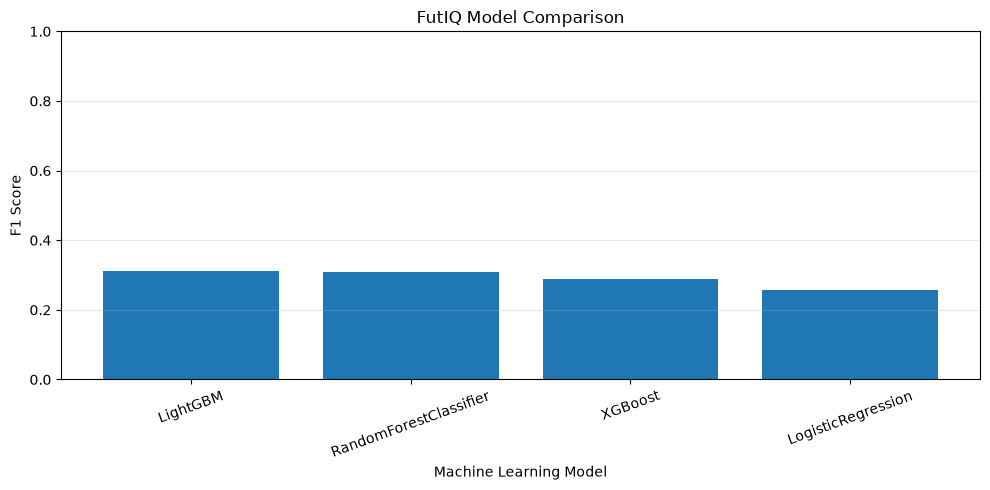

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.title("FutIQ Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")

plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
best_model_name = results_df.iloc[0]["Model"]

print("Best validation model:", best_model_name)

print(
    "Validation F1:",
    round(results_df.iloc[0]["F1 Score"], 4)
)

Best validation model: LightGBM
Validation F1: 0.3105


In [ ]:
# Retrain the selected model on all training data:The validation data helped us choose the algorithm. Now that we've selected it, we can use all available training data to build the final version.
# Create a fresh copy of the selected model
selected_model=clone(models[best_model_name])
# Create its preprocessing pipeline
final_pipeline=create_pipeline(selected_model)
# Encode all training labels using the existing encoder
y_train_encoded=label_encoder.transform(y_train)
# Train using the complete training dataset
final_pipeline.fit(X_train, y_train_encoded)
print("Final model trained: ", best_model_name)

Final model trained:  LightGBM


Model saved Successfully.
Model comparision Report saved.


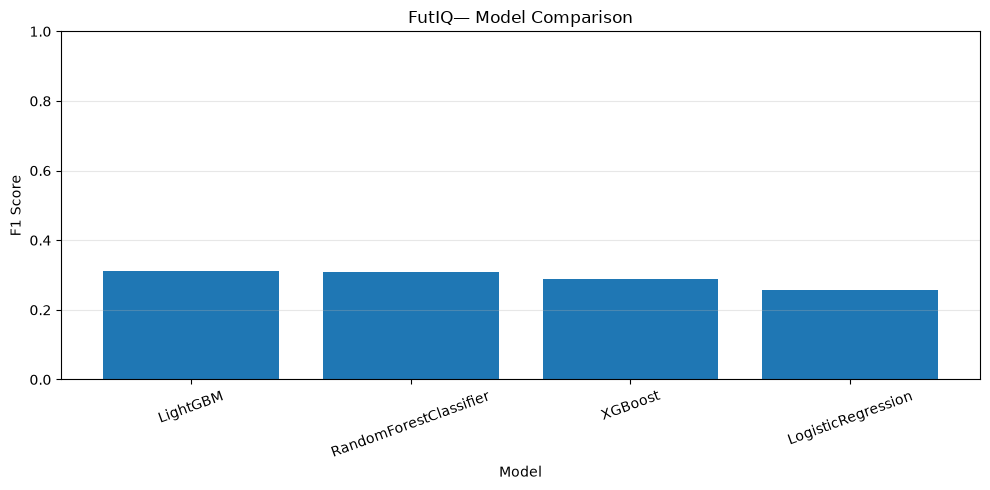

In [40]:
os.makedirs("../models", exist_ok=True)
model_bundle={
    "model":final_pipeline,
    "label_encoder": label_encoder,
    "feature_columns":list(X_train.columns),
    "model_name":best_model_name
}
joblib.dump(model_bundle, "../models/futiq_best_model.joblib")
print("Model saved Successfully.")
os.makedirs("../outputs/reports", exist_ok=True)
results_df.to_csv("../outputs/reports/model_comparision.csv", index=False)
print("Model comparision Report saved.")
os.makedirs("../outputs/plots", exist_ok=True)
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.title("FutIQ— Model Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../outputs/plots/model_comparision.png", dpi=300, bbox_inches="tight")

plt.show()